In [34]:

# Standard library
import copy
import json
import os
import random
from itertools import product

# Data processing
import joblib
import networkx as nx
import numpy as np
import pandas as pd
from pathlib import Path
# Visualization
import matplotlib.pyplot as plt

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F

# PyTorch Geometric
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
from torch_geometric.transforms import RandomLinkSplit

# Classical machine learning models
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    auc,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)


In [35]:
dataset = np.load("data/processed/link_prediction_dataset.npz")

X_train = dataset["X_train"]
X_val   = dataset["X_val"]
X_test  = dataset["X_test"]

y_train = dataset["y_train"]
y_val   = dataset["y_val"]
y_test  = dataset["y_test"]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


class Net(nn.Module):
    def __init__(
        self,
        in_channels,
        hidden_channels=32,
        out_channels=16,
        edge_feature_channels=29,
    ):
        super().__init__()

        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

        decoder_input_channels = (
            3 * out_channels + edge_feature_channels
        )

        self.decoder = nn.Sequential(
            nn.Linear(decoder_input_channels, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def encode(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        return self.conv2(x, edge_index)

    def decode(self, z, edge_label_index, edge_features):
        src = z[edge_label_index[0]]
        dst = z[edge_label_index[1]]

        edge_embedding = torch.cat(
            [
                src + dst,
                torch.abs(src - dst),
                src * dst,
                edge_features,
            ],
            dim=-1,
        )

        return self.decoder(edge_embedding).squeeze(-1)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# For trusted files you created yourself.
# weights_only=False may be needed for PyG Data objects
# on newer PyTorch versions.
saved = torch.load(
    "data/processed/link_prediction_graphs.pt",
    map_location="cpu",
    weights_only=False,
)

x = saved["x"].to(device)
train_data = saved["train_data"].to(device)
val_data = saved["val_data"].to(device)
test_data = saved["test_data"].to(device)

print("Node features:", x.shape)
print("Train graph:", train_data.edge_index.shape)
print("Validation candidates:", val_data.edge_label_index.shape)
print("Test candidates:", test_data.edge_label_index.shape)

Training: (1020, 29) (1020,)
Validation: (1274, 29) (1274,)
Test: (1274, 29) (1274,)
Node features: torch.Size([1800, 6])
Train graph: torch.Size([2, 9186])
Validation candidates: torch.Size([2, 1274])
Test candidates: torch.Size([2, 1274])


# Eval

In [53]:
DATASET_PATH = Path("data/processed/link_prediction_dataset.npz")
FEATURE_PATH = Path("data/processed/feature_metadata.json")
GRAPH_PATH = Path("data/processed/link_prediction_graphs.pt")
OUTPUT_DIR = Path("finetuning/finetuned_model_evaluation")
MODEL_PATHS = {
    "Logistic Regression": Path(
        r"finetuning\logistic_regression_accuracy_grid_results\best_logistic_regression.joblib"
    ),
    "Random Forest": Path(
        r"finetuning\randomforest_accuracy_grid_results\best_random_forest.joblib"
    ),
    "XGBoost": Path(
        r"finetuning\xgboost_accuracy_grid_results\best_xgboost.joblib"
    ),
    "CatBoost": Path(
        r"finetuning\catboost_accuracy_grid_results\best_catboost.cbm"
    ),
    # The GNN tuning script saves a PyTorch checkpoint, not joblib.
    "GNN": Path(
        r"finetuning\gnn_accuracy_grid_results\best_gnn.pt"
    ),
}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def evalu():
    # ==========================================
    # 2. LOAD DATA
    # ==========================================

    dataset = np.load(DATASET_PATH)

    X_val = dataset["X_val"]
    X_test = dataset["X_test"]
    y_val = dataset["y_val"].astype(int)
    y_test = dataset["y_test"].astype(int)

    # Load the graph splits for GNN inference.
    saved_graphs = torch.load(
        GRAPH_PATH,
        map_location="cpu",
        weights_only=False,
    )

    x = saved_graphs["x"].to(device)
    val_data = saved_graphs["val_data"].to(device)
    test_data = saved_graphs["test_data"].to(device)

    val_edge_features = torch.as_tensor(
        X_val, dtype=torch.float32, device=device
    )
    test_edge_features = torch.as_tensor(
        X_test, dtype=torch.float32, device=device
    )

    # Check that labels and candidate-edge features are aligned.
    assert len(X_val) == len(y_val)
    assert len(X_test) == len(y_test)
    assert X_val.shape[1] == X_test.shape[1]

    assert val_data.edge_label_index.shape[1] == len(X_val), (
        "Validation graph candidates and X_val have different lengths."
    )
    assert test_data.edge_label_index.shape[1] == len(X_test), (
        "Test graph candidates and X_test have different lengths."
    )

    print("Validation:", X_val.shape, y_val.shape)
    print("Test:", X_test.shape, y_test.shape)


    # ==========================================
    # 3. THRESHOLD SELECTION
    # ==========================================

    def find_best_f1_threshold(y_true, probabilities):
        """Select the threshold maximizing F1 on validation data."""
        y_true = np.asarray(y_true).astype(int)
        probabilities = np.asarray(probabilities, dtype=float)

        if len(y_true) != len(probabilities):
            raise ValueError("Labels and probabilities must have equal lengths.")

        if not np.isfinite(probabilities).all():
            raise ValueError("Probabilities contain NaN or infinite values.")

        thresholds = np.arange(0.05, 0.951, 0.01)

        scores = [
            f1_score(
                y_true,
                (probabilities >= threshold).astype(int),
                zero_division=0,
            )
            for threshold in thresholds
        ]

        best_score = max(scores)

        # If tied, prefer the threshold closest to 0.5.
        tied_indices = [
            i for i, score in enumerate(scores)
            if np.isclose(score, best_score)
        ]
        best_idx = min(
            tied_indices,
            key=lambda i: abs(thresholds[i] - 0.5),
        )

        return float(thresholds[best_idx]), float(scores[best_idx])


    # ==========================================
    # 4. GNN ARCHITECTURE
    # Must match the architecture used during tuning.
    # ==========================================

    class Net(nn.Module):
        def __init__(
            self,
            in_channels,
            hidden_channels=32,
            out_channels=16,
            edge_feature_channels=29,
            dropout=0.2,
        ):
            super().__init__()

            self.conv1 = GCNConv(in_channels, hidden_channels)
            self.conv2 = GCNConv(hidden_channels, out_channels)
            self.dropout = dropout

            decoder_input_channels = (
                3 * out_channels + edge_feature_channels
            )

            self.decoder = nn.Sequential(
                nn.Linear(decoder_input_channels, 64),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(64, 32),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(32, 1),
            )

        def encode(self, x, edge_index):
            z = F.relu(self.conv1(x, edge_index))
            z = F.dropout(z, p=self.dropout, training=self.training)
            return self.conv2(z, edge_index)

        def decode(self, z, edge_label_index, edge_features):
            src = z[edge_label_index[0]]
            dst = z[edge_label_index[1]]

            edge_embedding = torch.cat(
                [
                    src + dst,
                    torch.abs(src - dst),
                    src * dst,
                    edge_features,
                ],
                dim=-1,
            )

            return self.decoder(edge_embedding).squeeze(-1)



    def load_gnn(checkpoint_path):
        """Load a fine-tuned GNN checkpoint without retraining."""
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False,
        )

        saved_params = checkpoint["model_params"]

        # Keep only parameters accepted by Net.__init__().
        architecture_params = {
            key: saved_params[key]
            for key in (
                "hidden_channels",
                "out_channels",
                "dropout",
            )
            if key in saved_params
        }

        model = Net(
            in_channels=checkpoint.get(
                "input_channels", x.shape[1]
            ),
            edge_feature_channels=checkpoint.get(
                "edge_feature_channels", X_val.shape[1]
            ),
            **architecture_params,
        ).to(device)

        model.load_state_dict(checkpoint["model_state_dict"])
        model.eval()

        return model



    def gnn_probabilities(model, graph_data, edge_features):
        """Predict link probabilities for one saved graph split."""
        model.eval()

        with torch.no_grad():
            z = model.encode(
                graph_data.x,
                graph_data.edge_index,
            )

            logits = model.decode(
                z,
                graph_data.edge_label_index,
                edge_features,
            )

            probabilities = torch.sigmoid(logits).cpu().numpy()

        return probabilities


    # ==========================================
    # 5. LOAD MODELS AND SELECT THRESHOLDS
    # ==========================================

    predictions = {}
    loaded_models = {}
    threshold_rows = []

    for name, model_path in MODEL_PATHS.items():
        if not model_path.is_file():
            print(f"\nSkipping {name}: file not found: {model_path}")
            continue

        print(f"\nLoading {name}...")

        if name == "GNN":
            model = load_gnn(model_path)

            val_probs = gnn_probabilities(
                model, val_data, val_edge_features
            )
            test_probs = gnn_probabilities(
                model, test_data, test_edge_features
            )

            loaded_models[name] = model

    
        else:
            if name == "CatBoost":
                model = CatBoostClassifier()
                model.load_model(str(model_path))
            else:
                model = joblib.load(model_path)

            val_probs = model.predict_proba(X_val)[:, 1]
            test_probs = model.predict_proba(X_test)[:, 1]
            expected_features = getattr(model, "n_features_in_", None)

            # For pipelines, inspect the final estimator if necessary.
            if expected_features is None and hasattr(model, "named_steps"):
                expected_features = getattr(
                    model.steps[-1][1], "n_features_in_", None
                )

            # if expected_features is not None and expected_features != X_val.shape[1]:
            #     raise ValueError(
            #         f"{name} was trained on {expected_features} features, "
            #         f"but the current dataset has {X_val.shape[1]}. "
            #         "Retrain this model using the updated dataset."
            #     )

            val_probs = model.predict_proba(X_val)[:, 1]
            test_probs = model.predict_proba(X_test)[:, 1]

            loaded_models[name] = model


        # Select threshold exclusively using validation labels.
        threshold, validation_f1 = find_best_f1_threshold(
            y_val, val_probs
        )

        test_pred = (test_probs >= threshold).astype(int)

        predictions[name] = {
            "y_true": y_test.copy(),
            "y_probs": test_probs,
            "y_pred": test_pred,
            "threshold": threshold,
            "validation_f1": validation_f1,
        }

        threshold_rows.append({
            "Model": name,
            "Validation F1": validation_f1,
            "Threshold": threshold,
        })

        print(
            f"Validation F1={validation_f1:.4f} | "
            f"Threshold={threshold:.2f}"
        )

    if not predictions:
        raise RuntimeError(
            "No models were loaded. Check MODEL_PATHS and the working directory."
        )


    # ==========================================
    # 6. TEST METRICS
    # ==========================================

    rows = []

    for name, result in predictions.items():
        yt = result["y_true"]
        yp = result["y_pred"]
        probs = result["y_probs"]

        tn, fp, fn, tp = confusion_matrix(
            yt, yp, labels=[0, 1]
        ).ravel()

        rows.append({
            "Model": name,
            "Threshold": result["threshold"],
            "Validation F1": result["validation_f1"],
            "Accuracy": accuracy_score(yt, yp),
            "Balanced Accuracy": balanced_accuracy_score(yt, yp),
            "Precision": precision_score(yt, yp, zero_division=0),
            "Recall": recall_score(yt, yp, zero_division=0),
            "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
            "F1": f1_score(yt, yp, zero_division=0),
            "ROC-AUC": roc_auc_score(yt, probs),
            "Average Precision": average_precision_score(yt, probs),
            "TP": tp,
            "FP": fp,
            "TN": tn,
            "FN": fn,
        })

    results_df = (
        pd.DataFrame(rows)
        .sort_values("Average Precision", ascending=False)
        .reset_index(drop=True)
    )

    print("\n" + "=" * 110)
    print("FINE-TUNED MODEL TEST RESULTS")
    print("=" * 110)

    display_df = results_df.copy()

    score_columns = [
        "Validation F1",
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "Specificity",
        "F1",
        "ROC-AUC",
        "Average Precision",
    ]

    display_df[score_columns] = display_df[score_columns].round(4)
    display_df["Threshold"] = display_df["Threshold"].round(2)

    print(display_df.to_string(index=False))

    results_df.to_csv(
        OUTPUT_DIR / "test_metrics.csv",
        index=False,
    )

    pd.DataFrame(threshold_rows).to_csv(
        OUTPUT_DIR / "validation_thresholds.csv",
        index=False,
    )


    # ==========================================
    # 7. ROC AND PRECISION-RECALL CURVES
    # ==========================================

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    # ROC curves
    ax = axes[0]

    for name, result in predictions.items():
        fpr, tpr, _ = roc_curve(
            result["y_true"], result["y_probs"]
        )
        roc_auc = roc_auc_score(
            result["y_true"], result["y_probs"]
        )

        ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.3f})")

    ax.plot([0, 1], [0, 1], "--", label="Random baseline")
    ax.set_title("ROC Curves")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # Precision-recall curves
    ax = axes[1]

    for name, result in predictions.items():
        precision, recall, _ = precision_recall_curve(
            result["y_true"], result["y_probs"]
        )
        ap = average_precision_score(
            result["y_true"], result["y_probs"]
        )

        ax.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

    ax.set_title("Precision-Recall Curves")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / "roc_pr_curves.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()


    # ==========================================
    # 8. METRIC COMPARISON
    # ==========================================

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    results_df.set_index("Model")[
        ["Accuracy", "Balanced Accuracy", "Precision", "Recall", "F1"]
    ].plot(kind="bar", ax=axes[0])

    axes[0].set_title("Test Classification Metrics")
    axes[0].set_ylabel("Score")
    axes[0].set_ylim(0, 1)
    axes[0].tick_params(axis="x", rotation=35)
    axes[0].grid(axis="y", alpha=0.3)

    ap_sorted = results_df.sort_values("Average Precision")

    axes[1].barh(
        ap_sorted["Model"],
        ap_sorted["Average Precision"],
    )
    axes[1].set_title("Test Average Precision")
    axes[1].set_xlabel("Average Precision")
    axes[1].set_xlim(0, 1)
    axes[1].grid(axis="x", alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / "metric_comparison.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()


    # ==========================================
    # 9. CONFUSION MATRICES
    # ==========================================

    n_models = len(predictions)

    fig, axes = plt.subplots(
        1,
        n_models,
        figsize=(4 * n_models, 4),
        squeeze=False,
    )

    for ax, (name, result) in zip(axes.ravel(), predictions.items()):
        cm = confusion_matrix(
            result["y_true"],
            result["y_pred"],
            labels=[0, 1],
        )

        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Negative", "Positive"],
        ).plot(
            ax=ax,
            values_format="d",
            colorbar=False,
        )

        ax.set_title(
            f"{name}\nThreshold={result['threshold']:.2f}"
        )

    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / "confusion_matrices.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()


    # ==========================================
    # 10. OUTPUTS
    # ==========================================

    print(f"\nResults saved to: {OUTPUT_DIR.resolve()}")
    print("Available variables:")
    print("  results_df   - test metrics for loaded models")
    print("  predictions  - test probabilities, labels, and thresholds")
    print("  loaded_models - loaded fine-tuned model objects")

    return {
        "loaded_models": loaded_models,
        "predictions": predictions,
        "X_val": X_val,
        "y_val": y_val,
        "val_data": val_data,
        "val_edge_features": val_edge_features,
        "device": device,
        "output_dir": OUTPUT_DIR / "feature_importance",
    }

In [54]:

def feature_importance(context, feature_names=None, n_repeats=10):
    """
    Inspect native and permutation feature importance for every loaded model.

    Permutation importance = baseline validation accuracy minus accuracy
    after shuffling one feature.

    Returns:
        native_df: native importance for models that support it
        permutation_df: permutation importance for every loaded model
    """
    import re

    loaded_models = context["loaded_models"]
    predictions = context["predictions"]
    X_val = context["X_val"]
    y_val = context["y_val"]
    val_data = context["val_data"]
    val_edge_features = context["val_edge_features"]
    device = context["device"]
    output_dir = context["output_dir"]

    n_features = X_val.shape[1]


    FEATURE_PATH = Path("data/processed/feature_metadata.json")

    if feature_names is None:
        with FEATURE_PATH.open("r", encoding="utf-8") as f:
            metadata = json.load(f)

        # Adjust this extraction to match the structure of your JSON file.
        if isinstance(metadata, list):
            feature_names = metadata
        elif "feature_names" in metadata:
            feature_names = metadata["feature_names"]
        elif "features" in metadata:
            features = metadata["features"]
            feature_names = (
                [item["name"] for item in features]
                if features and isinstance(features[0], dict)
                else features
            )
        else:
            raise ValueError(
                f"Could not find feature names in {FEATURE_PATH}. "
                f"Available keys: {list(metadata.keys())}"
            )

        feature_names = [str(name) for name in feature_names]

    if len(feature_names) != n_features:
        raise ValueError(
            f"Expected {n_features} feature names, "
            f"received {len(feature_names)}."
        )

    output_dir.mkdir(parents=True, exist_ok=True)

    rng = np.random.default_rng(42)

    # ------------------------------------------
    # A. Native feature importance
    # ------------------------------------------

    native_rows = []

    for name, model in loaded_models.items():
        importance = None
        method = None

        if name == "Logistic Regression":
            # Works with a fitted sklearn Pipeline or a standalone estimator.
            estimator = model

            if hasattr(model, "named_steps"):
                estimator = next(
                    (
                        step
                        for step in reversed(
                            list(model.named_steps.values())
                        )
                        if hasattr(step, "coef_")
                    ),
                    None,
                )

            if estimator is not None and hasattr(estimator, "coef_"):
                importance = np.abs(estimator.coef_).mean(axis=0)
                method = "Absolute coefficient"

        elif name == "Random Forest":
            if hasattr(model, "feature_importances_"):
                importance = model.feature_importances_
                method = "Impurity-based importance"

        elif name == "XGBoost":
            if hasattr(model, "feature_importances_"):
                importance = model.feature_importances_
                method = "XGBoost feature importance"

        elif name == "CatBoost":
            importance = model.get_feature_importance()
            method = "CatBoost feature importance"

        # The GNN has no directly comparable built-in importance for
        # the 29 input edge features. We assess those by permutation below.

        if importance is None:
            print(f"{name}: no native importance available.")
            continue

        importance = np.asarray(importance).reshape(-1)

        if len(importance) != n_features:
            print(
                f"{name}: expected {n_features} importance values, "
                f"got {len(importance)}. Skipping."
            )
            continue

        for feature, score in zip(feature_names, importance):
            native_rows.append({
                "Model": name,
                "Feature": feature,
                "Importance": float(score),
                "Method": method,
            })

    native_df = pd.DataFrame(
        native_rows,
        columns=["Model", "Feature", "Importance", "Method"],
    )

    if not native_df.empty:
        native_df.to_csv(
            output_dir / "native_feature_importance.csv",
            index=False,
        )

        for name in native_df["Model"].unique():
            print(f"\n{name} — native top 10")
            print(
                native_df[native_df["Model"] == name]
                .nlargest(10, "Importance")[
                    ["Feature", "Importance"]
                ]
                .to_string(index=False)
            )

    # ------------------------------------------
    # B. Permutation importance for all models
    # ------------------------------------------

    permutation_rows = []

    # Use the same threshold chosen from validation F1 during evaluation.
    for name, model in loaded_models.items():
        threshold = predictions[name]["threshold"]

        if name == "GNN":
            original_features = (
                val_edge_features.detach().cpu().numpy().copy()
            )

            model.eval()
            with torch.no_grad():
                z = model.encode(
                    val_data.x,
                    val_data.edge_index,
                )
                baseline_logits = model.decode(
                    z,
                    val_data.edge_label_index,
                    val_edge_features,
                )
                baseline_probs = torch.sigmoid(
                    baseline_logits
                ).cpu().numpy()

        else:
            original_features = np.asarray(X_val).copy()
            baseline_probs = model.predict_proba(X_val)[:, 1]

        baseline_pred = (baseline_probs >= threshold).astype(int)
        baseline_accuracy = accuracy_score(y_val, baseline_pred)

        for j, feature in enumerate(feature_names):
            drops = []

            for _ in range(n_repeats):
                permuted = original_features.copy()
                permuted[:, j] = rng.permutation(permuted[:, j])

                if name == "GNN":
                    permuted_tensor = torch.as_tensor(
                        permuted,
                        dtype=torch.float32,
                        device=device,
                    )

                    with torch.no_grad():
                        logits = model.decode(
                            z,
                            val_data.edge_label_index,
                            permuted_tensor,
                        )
                        probs = torch.sigmoid(logits).cpu().numpy()
                else:
                    probs = model.predict_proba(permuted)[:, 1]

                pred = (probs >= threshold).astype(int)
                permuted_accuracy = accuracy_score(y_val, pred)

                drops.append(baseline_accuracy - permuted_accuracy)

            permutation_rows.append({
                "Model": name,
                "Feature": feature,
                "Importance": float(np.mean(drops)),
                "Std": float(np.std(drops)),
                "Baseline_Validation_Accuracy": baseline_accuracy,
            })

    permutation_df = pd.DataFrame(permutation_rows)

    permutation_df.to_csv(
        output_dir / "permutation_feature_importance.csv",
        index=False,
    )

    # ------------------------------------------
    # C. Print and plot top features per model
    # ------------------------------------------

    for name in loaded_models:
        subset = permutation_df[
            permutation_df["Model"] == name
        ].sort_values("Importance", ascending=False)

        print(f"\n{name} — permutation top 10")
        print(
            subset.head(10)[["Feature", "Importance", "Std"]]
            .round(5)
            .to_string(index=False)
        )

        plot_data = subset.head(15).sort_values("Importance")

        fig, ax = plt.subplots(figsize=(9, 6))
        ax.barh(
            plot_data["Feature"],
            plot_data["Importance"],
            xerr=plot_data["Std"],
        )
        ax.axvline(0, linestyle="--", linewidth=1)
        ax.set_title(f"{name}: Permutation Feature Importance")
        ax.set_xlabel("Drop in validation accuracy")
        ax.set_ylabel("Feature")
        ax.grid(axis="x", alpha=0.3)
        plt.tight_layout()

        safe_name = re.sub(r"[^a-zA-Z0-9_-]+", "_", name.lower())
        plt.savefig(
            output_dir / f"{safe_name}_feature_importance.png",
            dpi=150,
            bbox_inches="tight",
        )
        plt.show()
        plt.close(fig)

    print(f"\nFeature importance saved to: {output_dir.resolve()}")

    return native_df, permutation_df


Validation: (1274, 29) (1274,)
Test: (1274, 29) (1274,)

Loading Logistic Regression...
Validation F1=0.8584 | Threshold=0.31

Loading Random Forest...
Validation F1=0.8548 | Threshold=0.54

Loading XGBoost...
Validation F1=0.8537 | Threshold=0.53

Loading CatBoost...
Validation F1=0.8567 | Threshold=0.47

Loading GNN...
Validation F1=0.8582 | Threshold=0.45

FINE-TUNED MODEL TEST RESULTS
              Model  Threshold  Validation F1  Accuracy  Balanced Accuracy  Precision  Recall  Specificity     F1  ROC-AUC  Average Precision  TP  FP  TN  FN
                GNN       0.45         0.8582    0.8658             0.8658     0.8426  0.8995       0.8320 0.8702   0.9167             0.9136 573 107 530  64
           CatBoost       0.47         0.8567    0.8650             0.8650     0.8528  0.8823       0.8477 0.8673   0.9092             0.9069 562  97 540  75
      Random Forest       0.54         0.8548    0.8603             0.8603     0.8331  0.9011       0.8195 0.8658   0.9138            

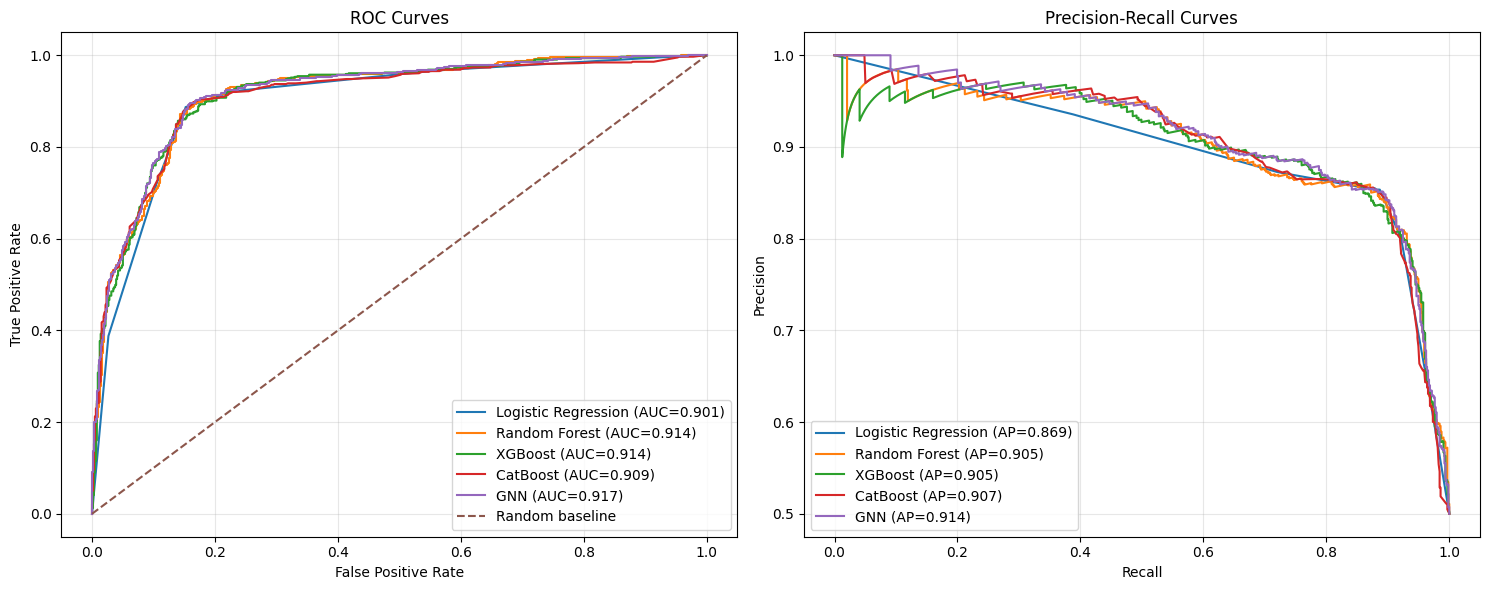

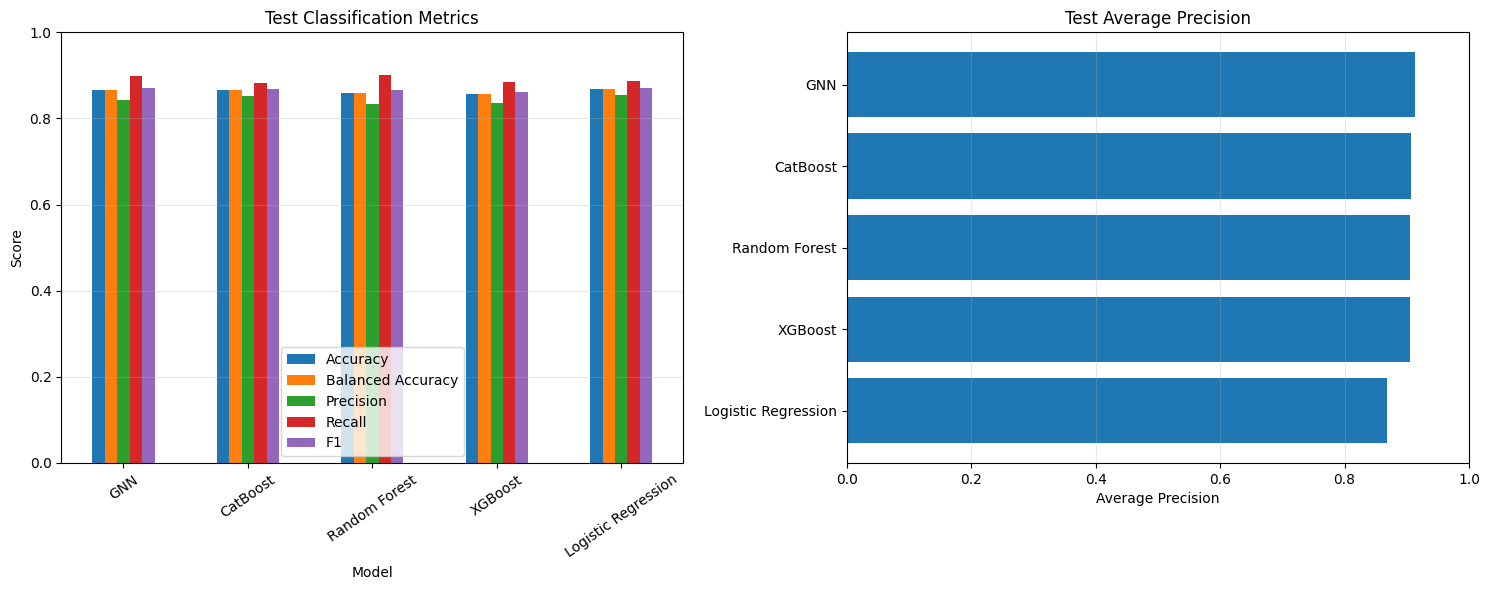

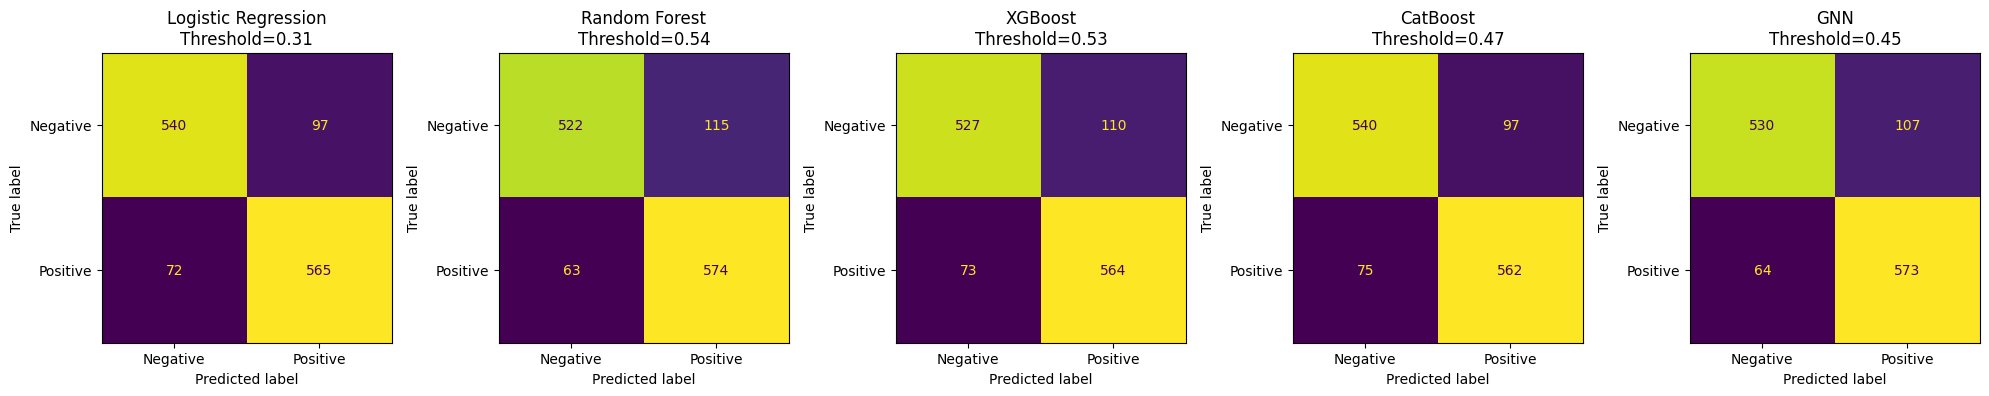


Results saved to: C:\Users\SemKj\Downloads\network_prediction\finetuning\finetuned_model_evaluation
Available variables:
  results_df   - test metrics for loaded models
  predictions  - test probabilities, labels, and thresholds
  loaded_models - loaded fine-tuned model objects
GNN: no native importance available.

Logistic Regression — native top 10
               Feature  Importance
        same_community    1.029330
shortest_path_distance    0.182338
        category_sum_a    0.000000
        category_sum_b    0.000000
        category_sum_c    0.000000
        category_sum_d    0.000000
        category_sum_e    0.000000
        category_sum_f    0.000000
   category_abs_diff_a    0.000000
   category_abs_diff_b    0.000000

Random Forest — native top 10
                Feature  Importance
         same_community    0.350919
             katz_score    0.231213
 shortest_path_distance    0.124883
preferential_attachment    0.069576
     endpoint_homophily    0.041943
            ad

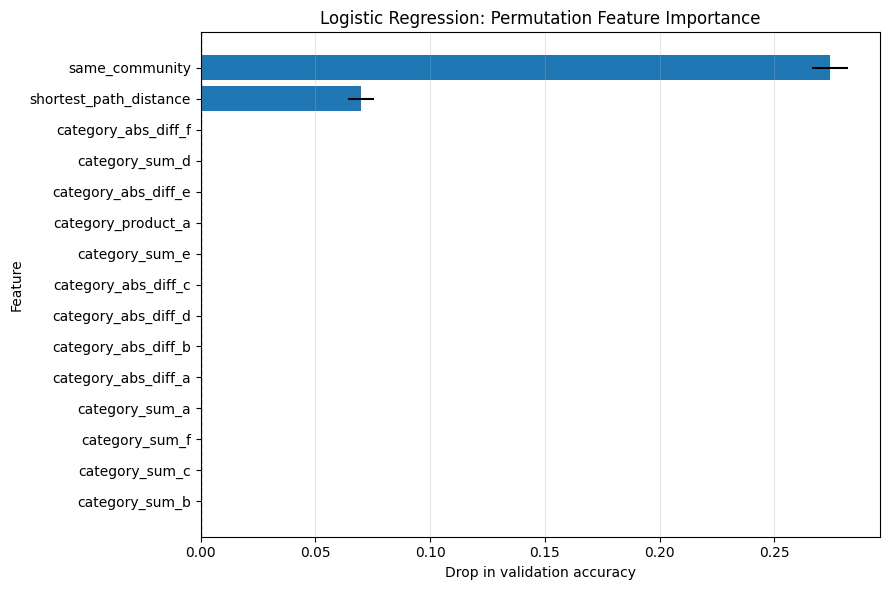


Random Forest — permutation top 10
                Feature  Importance     Std
         same_community     0.24490 0.01172
             katz_score     0.00361 0.00220
preferential_attachment     0.00251 0.00092
            adamic_adar     0.00204 0.00094
         category_sum_f     0.00196 0.00095
    category_abs_diff_f     0.00181 0.00122
     endpoint_homophily     0.00181 0.00145
         category_sum_e     0.00141 0.00092
    resource_allocation     0.00133 0.00111
    category_abs_diff_e     0.00110 0.00072


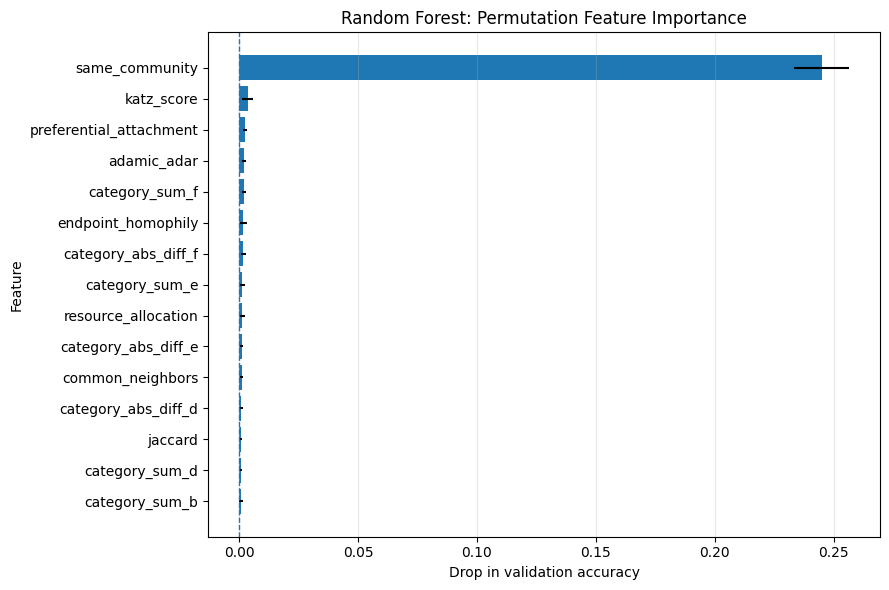


XGBoost — permutation top 10
                Feature  Importance     Std
         same_community     0.26562 0.01101
             katz_score     0.01334 0.00385
preferential_attachment     0.00534 0.00221
     endpoint_homophily     0.00298 0.00121
    category_abs_diff_f     0.00204 0.00190
    category_abs_diff_e     0.00157 0.00099
 shortest_path_distance     0.00149 0.00170
         category_sum_e     0.00094 0.00077
         category_sum_f     0.00071 0.00055
         category_sum_c     0.00047 0.00063


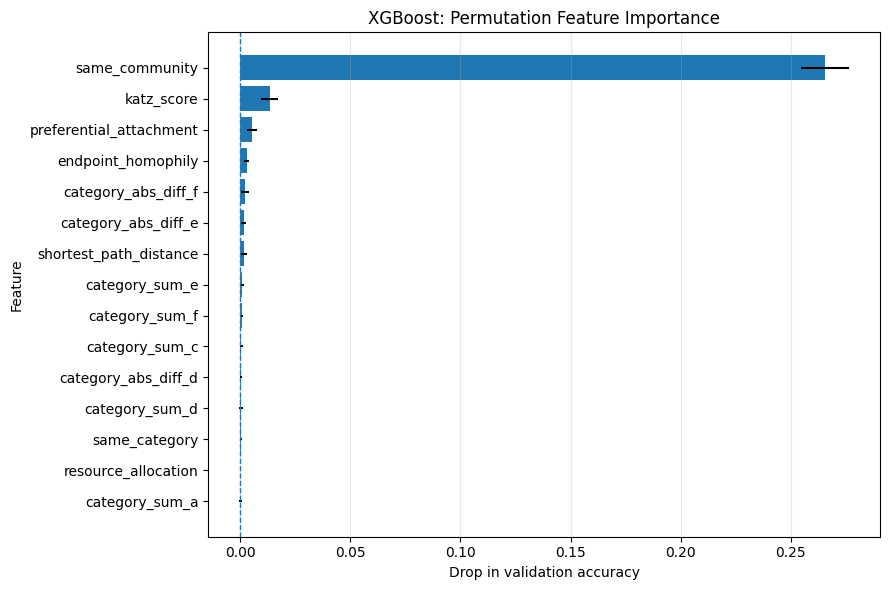


CatBoost — permutation top 10
                Feature  Importance     Std
         same_community     0.31389 0.01367
 shortest_path_distance     0.02096 0.00322
preferential_attachment     0.00549 0.00111
    category_abs_diff_f     0.00243 0.00074
     endpoint_homophily     0.00118 0.00039
       common_neighbors     0.00102 0.00145
             katz_score     0.00071 0.00065
                jaccard     0.00031 0.00063
         category_sum_d     0.00008 0.00024
         category_sum_b     0.00008 0.00042


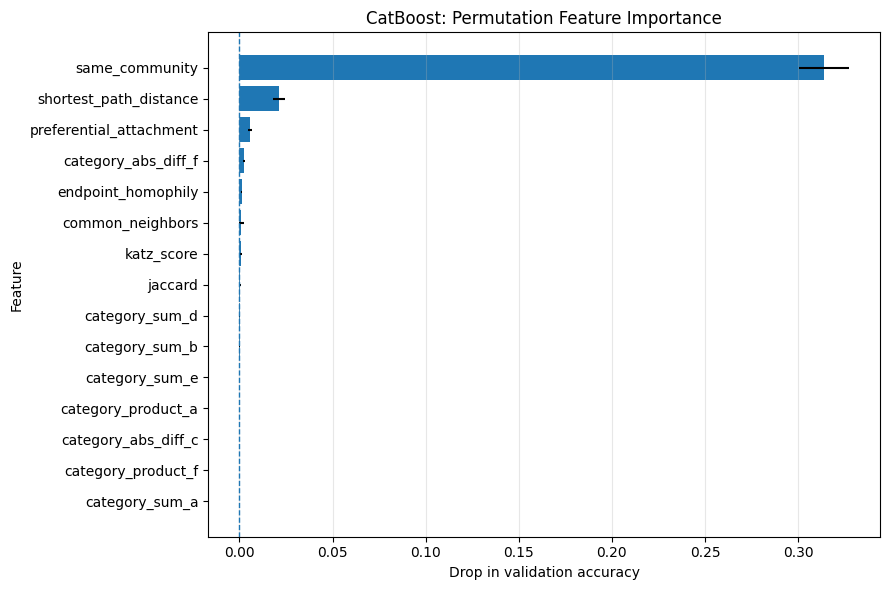


GNN — permutation top 10
                Feature  Importance     Std
         same_community     0.20754 0.01294
 shortest_path_distance     0.07119 0.00816
preferential_attachment     0.02465 0.00578
       common_neighbors     0.01429 0.00499
            adamic_adar     0.00385 0.00184
         category_sum_d     0.00181 0.00086
         category_sum_c     0.00173 0.00059
          same_category     0.00157 0.00061
    category_abs_diff_a     0.00118 0.00080
         category_sum_b     0.00102 0.00050


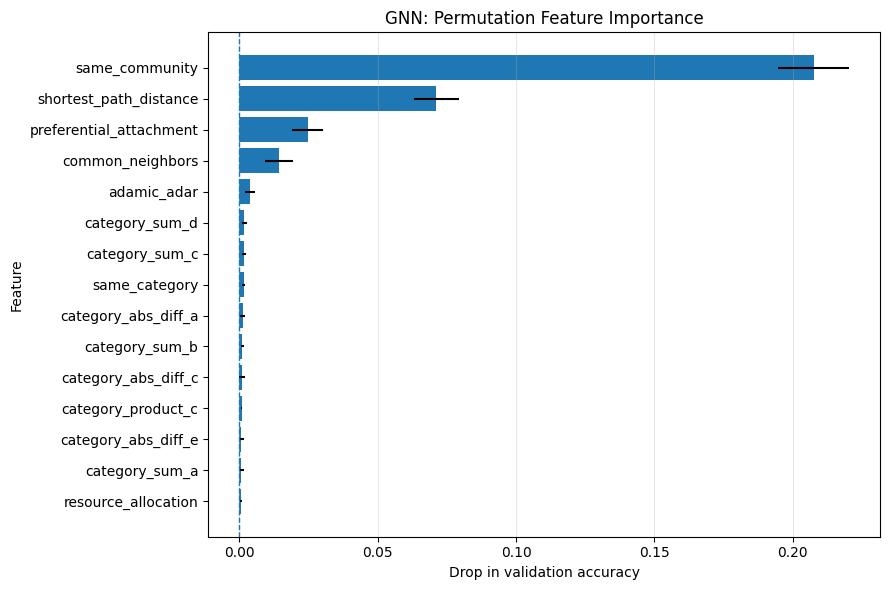


Feature importance saved to: C:\Users\SemKj\Downloads\network_prediction\finetuning\finetuned_model_evaluation\feature_importance


In [55]:
evaluation = evalu()

native_importance, permutation_importance = feature_importance(
    evaluation,
    n_repeats=10,
)


In [52]:
from catboost import CatBoostClassifier
from pathlib import Path

model_path = Path(
    "finetuning/catboost_accuracy_grid_results/best_catboost.cbm"
)

model = CatBoostClassifier()
model.load_model(str(model_path))

importances = model.get_feature_importance()

print("Importance array shape:", importances.shape)
print("Number of features:", len(importances))
print("Dataset feature count:", X_val.shape[1])

assert len(importances) == X_val.shape[1], (
    f"Model has {len(importances)} feature importances, "
    f"but dataset has {X_val.shape[1]} features."
)

val_probs = model.predict_proba(X_val)[:, 1]
print("Validation predictions:", val_probs.shape)

Importance array shape: (29,)
Number of features: 29
Dataset feature count: 29
Validation predictions: (1274,)
